Ciarra R. Barnett

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

df = pd.read_parquet("../data/ff_market_daily.parquet")

df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

print(f"{len(df):,} trading-day observations")
print(f"Date range: {df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")

display(df[["date", "market_return_pct"]].head())

26,296 trading-day observations
Date range: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


In [2]:
df["today_state"] = np.where(df["market_return_pct"] > 0, "Up", "Down")

df["next_state"] = df["today_state"].shift(-1)

df_two = df.dropna(subset=["next_state"]).copy()

display(df_two[["date", "market_return_pct","today_state", "next_state"]].head(10))

,date,market_return_pct,today_state,next_state
0,1926-07-01,0.10,Up,Up
1,1926-07-02,0.46,Up,Up
2,1926-07-06,0.18,Up,Up
3,1926-07-07,0.10,Up,Up
4,1926-07-08,0.23,Up,Down
5,1926-07-09,-0.70,Down,Up
6,1926-07-10,0.62,Up,Up
7,1926-07-12,0.05,Up,Up
8,1926-07-13,0.49,Up,Up
9,1926-07-14,0.05,Up,Down


In [3]:
joint_pmf = pd.crosstab(df_two["today_state"],df_two["next_state"],normalize="all")

print("Joint PMF:")
display(joint_pmf)

print("Today's marginal probabilities:")
display(joint_pmf.sum(axis=1))

print("Next day's marginal probabilities:")
display(joint_pmf.sum(axis=0))

conditional_pmf = pd.crosstab(df_two["today_state"],df_two["next_state"],normalize="index")

print("Conditional PMF:")
display(conditional_pmf)

Joint PMF:


next_state,Down,Up
today_state,,
Down,0.224720,0.228142
Up,0.228142,0.318996


Today's marginal probabilities:


today_state
Down    0.452862
Up      0.547138
dtype: float64

Next day's marginal probabilities:


next_state
Down    0.452862
Up      0.547138
dtype: float64

Conditional PMF:


next_state,Down,Up
today_state,,
Down,0.496221,0.503779
Up,0.416974,0.583026


In [4]:
print("P(Up tomorrow | Down today):",conditional_pmf.loc["Down", "Up"])

print("P(Up tomorrow | Up today):",conditional_pmf.loc["Up", "Up"])

P(Up tomorrow | Down today): 0.5037789721195834
P(Up tomorrow | Up today): 0.5830263432265239


 Up transitions are more common then down transitions. 54.71% of trading days are up, and 45.28% of trading days are down. Also. the most common transsition is up to up is 31.89%. 
 
 You are more likely to transiton to an up day to another up day. The probability is 58.30% compared to 50.37%. This means that today's market direction provides some information about tommorrow's direction. 

In [5]:
bins = [-np.inf, -1, -0.1, 0.1, 1, np.inf]

labels = ["Large loss","Small loss","Near zero","Small gain","Large gain"]

df["market_state_5"] = pd.cut(df["market_return_pct"],bins=bins,labels=labels)

counts = df["market_state_5"].value_counts(sort=False)

print("Days in each category:")
display(counts)

print("Most common:", counts.idxmax())
print("Least common:", counts.idxmin())

Days in each category:


market_state_5
Large loss    2759
Small loss    7452
Near zero     3441
Small gain    9785
Large gain    2859
Name: count, dtype: int64

Most common: Small gain
Least common: Large loss


In [6]:
df["next_state_5"] = df["market_state_5"].shift(-1)

df_five = df.dropna(subset=["market_state_5", "next_state_5"]).copy()

joint_5 = pd.crosstab(df_five["market_state_5"],df_five["next_state_5"],normalize="all")

print("Joint PMF:")
display(joint_5)

print("Today's Marginals:")
display(joint_5.sum(axis=1))

print("Tomorrow's Marginals:")
display(joint_5.sum(axis=0))

print("Most common transitions:")
display(joint_5.stack().sort_values(ascending=False).head())

Joint PMF:


next_state_5,Large loss,Small loss,Near zero,Small gain,Large gain
market_state_5,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928


Today's Marginals:


market_state_5
Large loss    0.104925
Small loss    0.283400
Near zero     0.130861
Small gain    0.372086
Large gain    0.108728
dtype: float64

Tomorrow's Marginals:


next_state_5
Large loss    0.104925
Small loss    0.283400
Near zero     0.130823
Small gain    0.372124
Large gain    0.108728
dtype: float64

Most common transitions:


market_state_5  next_state_5
Small gain      Small gain      0.159422
                Small loss      0.100057
Small loss      Small gain      0.097775
                Small loss      0.088648
Small gain      Near zero       0.055029
dtype: float64

Small gains were the most common with 9,785 days which is 37.20%. Large losses were the least common with 2,759 days which is 10.49%. This shows that small postive returns occurred more frequently than large negatives returns. 

 The most common change is a small gain followed by another small gain 15.94%. Other cmmon changes are small gains followed by smalled losses, 10.01% and small losses followed by small gains 9.78%. Overall, small market chnages chappen more often than the larger ones. 

For all five market states small gain and small losee were the two most likely next-day outcomes. The probabilities vary and aren't close to 0.20. Small gains are more likely but predicting the next days market catergory is still difficult. 

In [7]:
df["next_return_pct"] = df["market_return_pct"].shift(-1)

summary = (df.groupby("market_state_5", observed=False)["next_return_pct"].describe())

display(summary[["mean", "min", "max", "std"]].round(3))

,mean,min,max,std
market_state_5,,,,
Large loss,-0.038,-17.41,11.22,1.721
Small loss,-0.044,-11.23,11.36,1.010
Near zero,0.015,-8.19,5.49,0.826
Small gain,0.107,-8.25,8.67,0.832
Large gain,0.163,-12.00,15.67,1.384


The average next-day returns a range from -0.044% to 0.163%. The biggest loss -17.41% happened after a large loss day, while the biggest gain 15.67% happened after a large gain day. Large loss days had the most variation 1.721 which is followed by large gain days 1.384. 

In [8]:
df["y_t"] = pd.qcut(df["market_return_pct"],q=21,labels=False)

df["y_tp1"] = df["y_t"].shift(-1)

df["next_return_pct"] = df["market_return_pct"].shift(-1)

df_21 = df.dropna(subset=["y_t", "y_tp1", "next_return_pct"]).copy()

df_21["y_t"] = df_21["y_t"].astype(int)
df_21["y_tp1"] = df_21["y_tp1"].astype(int)

print("Number of bins:", df["y_t"].nunique())
display(df_21[["market_return_pct", "y_t", "y_tp1"]].head())

Number of bins: 21


,market_return_pct,y_t,y_tp1
0,0.10,10,15
1,0.46,15,11
2,0.18,11,10
3,0.10,10,12
4,0.23,12,3


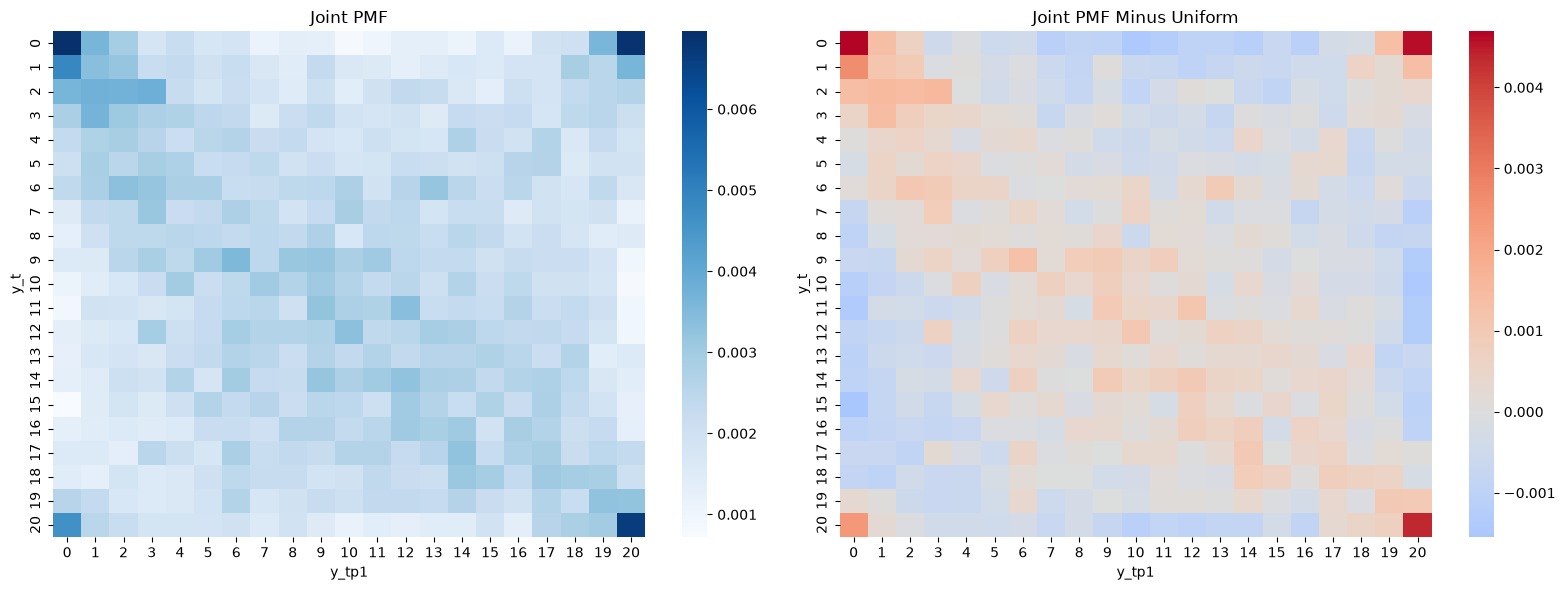

In [9]:
joint_21 = pd.crosstab(df_21["y_t"],df_21["y_tp1"],normalize="all")

joint_diff = joint_21 - 1 / (21**2)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(joint_21, cmap="Blues", ax=axes[0])
axes[0].set_title("Joint PMF")

sns.heatmap(joint_diff,cmap="coolwarm",center=0,ax=axes[1])
axes[1].set_title("Joint PMF Minus Uniform")

plt.tight_layout()
plt.show()

The heatmaps shows that large makert changes are sometimes followed by other large changes. Similar returns can also happen on back to back days. Overall there are some patterns but predicting the next day's return is still difficult. 

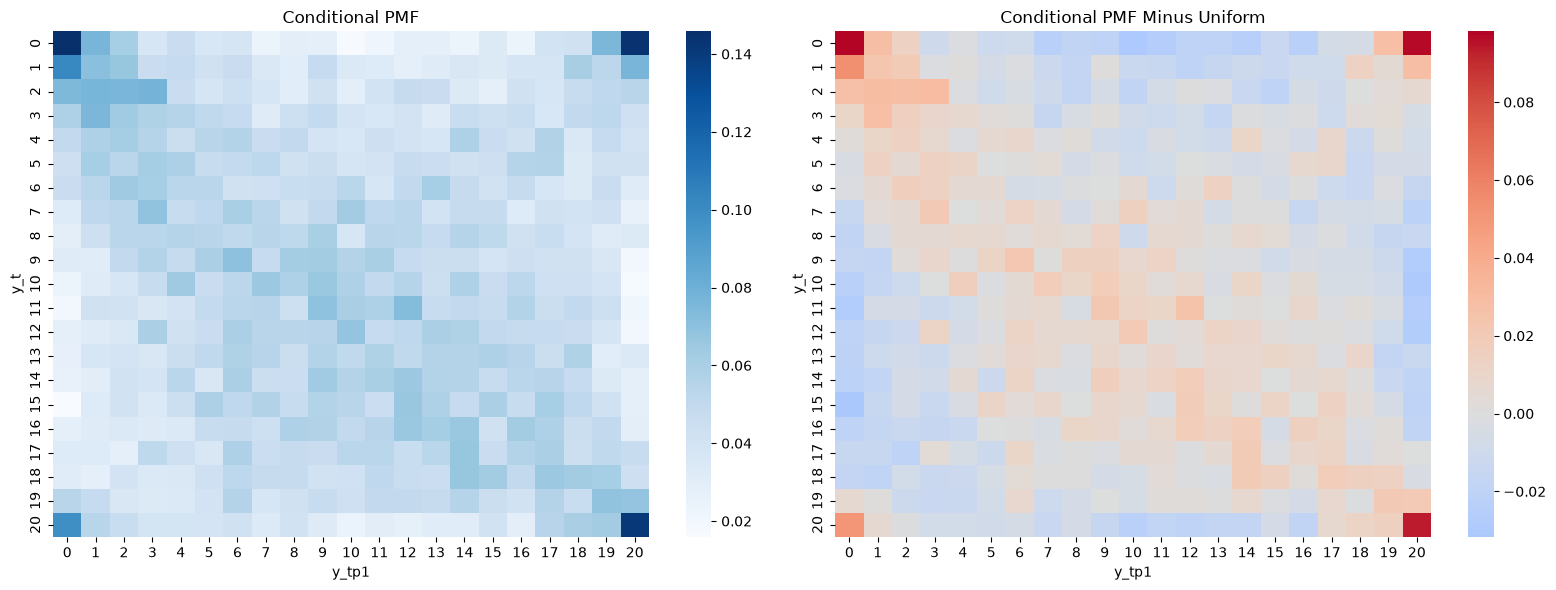

In [11]:
conditional_21 = pd.crosstab(df_21["y_t"],df_21["y_tp1"],normalize="index")

conditional_diff = conditional_21 - 1 / 21

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(conditional_21,cmap="Blues",ax=axes[0])
axes[0].set_title("Conditional PMF")

sns.heatmap( conditional_diff,cmap="coolwarm",center=0,ax=axes[1])
axes[1].set_title("Conditional PMF Minus Uniform")

plt.tight_layout()
plt.show()

The condtional PMF heatmaps shows that large markets changes are more likely to be followed by other large changes. The slight diagonal pattern shows that similar returns can happen on consecutive days. 

In [17]:
conditional_5 = pd.crosstab(df_five["market_state_5"], df_five["next_state_5"],normalize="index")

print("Conditional PMF:")
display(conditional_5.round(3))

for state, row in conditional_5.iterrows():
    print(f"\n{state}:")
    print(row.nlargest(2))

Conditional PMF:


next_state_5,Large loss,Small loss,Near zero,Small gain,Large gain
market_state_5,,,,,
Large loss,0.203,0.259,0.086,0.265,0.186
Small loss,0.125,0.313,0.121,0.345,0.097
Near zero,0.071,0.321,0.160,0.377,0.071
Small gain,0.067,0.269,0.148,0.428,0.088
Large gain,0.127,0.235,0.107,0.348,0.183



Large loss:
next_state_5
Small gain    0.264951
Small loss    0.259152
Name: Large loss, dtype: float64

Small loss:
next_state_5
Small gain    0.345008
Small loss    0.312802
Name: Small loss, dtype: float64

Near zero:
next_state_5
Small gain    0.376925
Small loss    0.320837
Name: Near zero, dtype: float64

Small gain:
next_state_5
Small gain    0.428455
Small loss    0.268908
Name: Small gain, dtype: float64

Large gain:
next_state_5
Small gain    0.347674
Small loss    0.234697
Name: Large gain, dtype: float64


,min,mean,max,std
y_t,,,,
0,-17.41,-0.014,11.22,2.140
1,-7.36,-0.077,6.36,1.286
2,-8.79,-0.097,11.36,1.228
3,-8.28,-0.059,6.16,1.050
4,-6.89,-0.024,4.56,0.989
5,-11.23,-0.023,6.37,1.025
6,-3.94,-0.030,7.37,0.930
7,-3.40,-0.014,4.76,0.836
8,-6.00,0.026,5.49,0.853


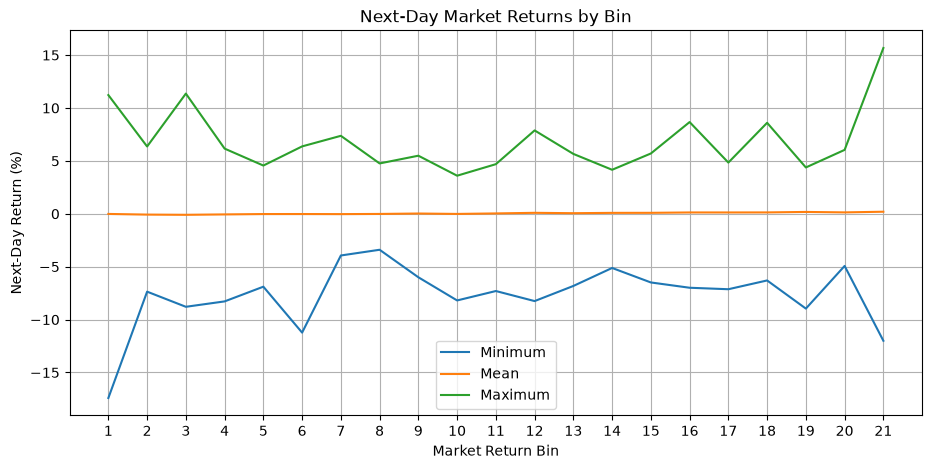

In [12]:
summary_21 = (df_21.groupby("y_t")["next_return_pct"].agg(["min", "mean", "max", "std"]))

display(summary_21.round(3))

plt.figure(figsize=(11, 5))

plt.plot(summary_21.index + 1, summary_21["min"], label="Minimum")
plt.plot(summary_21.index + 1, summary_21["mean"], label="Mean")
plt.plot(summary_21.index + 1, summary_21["max"], label="Maximum")

plt.xlabel("Market Return Bin")
plt.ylabel("Next-Day Return (%)")
plt.title("Next-Day Market Returns by Bin")
plt.xticks(range(1, 22))
plt.legend()
plt.grid(True)
plt.show()

The graph shows that average next day returns stay close to zero but increase slightly across the groups. The biggest loss was -17.41% and the biggest gain was 15.67%. Extreme market days had a wider range of next day returns, making the market difficult to predict.

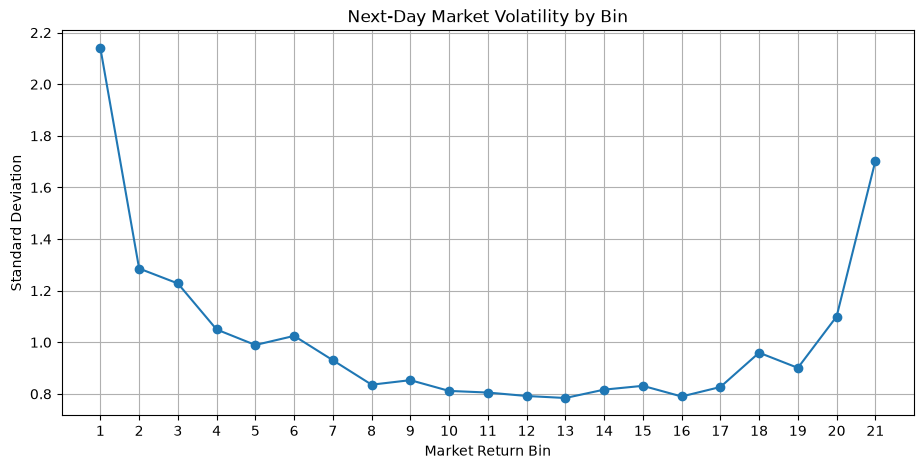

In [13]:
plt.figure(figsize=(11, 5))

plt.plot(summary_21.index + 1,summary_21["std"],marker="o")

plt.xlabel("Market Return Bin")
plt.ylabel("Standard Deviation")
plt.title("Next-Day Market Volatility by Bin")
plt.xticks(range(1, 22))
plt.grid(True)
plt.show()

The highest standard deviations occurred in the bins with the largest losses 2.140 and largest gains 1.703. This shows that extreme market changes were followed by greater volatility, while smaller changes generally had more stable returns 

Predicting the market is difficult because daily returns can change unexpectedly. Although the data shows some patterns, they are not strong enough to reliably predict the next day's return.